# Labeling a game-1 frame

Edit `spots` in the next cell and run it. Each value is one pixel on the frame: **x** counts from the left edge, **y** counts from the top edge. The picture is 1280 by 720, so the top-left pixel is `(0, 0)` and the bottom-right is `(1279, 719)`.

Court meters use the same directions as the tracker. The origin is the center of the court on the ground. **+X** is horizontal, to the right, the same way pixel x grows. **+Y** is vertical, downward, the same way pixel y grows, so the near baseline is the one toward the bottom of the frame. **+Z** is up. `left` and `right` are the sidelines. `near` and `far` are the baselines, service lines, and the net.

| Name | Where it is on the court | Meters (X, Y, Z) |
| --- | --- | --- |
| `doubles_near_left` | Doubles corner, near baseline and left sideline | (−5.485, 11.885, 0) |
| `doubles_near_right` | Doubles corner, near baseline and right sideline | (5.485, 11.885, 0) |
| `doubles_far_left` | Doubles corner, far baseline and left sideline | (−5.485, −11.885, 0) |
| `doubles_far_right` | Doubles corner, far baseline and right sideline | (5.485, −11.885, 0) |
| `singles_near_left` | Near baseline where the left singles sideline meets it | (−4.115, 11.885, 0) |
| `singles_near_right` | Near baseline where the right singles sideline meets it | (4.115, 11.885, 0) |
| `singles_far_left` | Far baseline where the left singles sideline meets it | (−4.115, −11.885, 0) |
| `singles_far_right` | Far baseline where the right singles sideline meets it | (4.115, −11.885, 0) |
| `service_near_left` | Near service line meets the left singles sideline, 6.40 m from the net | (−4.115, 6.40, 0) |
| `service_near_right` | Near service line meets the right singles sideline | (4.115, 6.40, 0) |
| `service_far_left` | Far service line meets the left singles sideline | (−4.115, −6.40, 0) |
| `service_far_right` | Far service line meets the right singles sideline | (4.115, −6.40, 0) |
| `baseline_near` | Center mark on the near baseline | (0, 11.885, 0) |
| `baseline_far` | Center mark on the far baseline | (0, −11.885, 0) |
| `service_near` | The near T: center service line meets the near service line | (0, 6.40, 0) |
| `service_far` | The far T | (0, −6.40, 0) |
| `net_post_left` | Top of the left net post, 0.914 m outside the doubles sideline | (−6.399, 0, 1.07) |
| `net_post_right` | Top of the right net post | (6.399, 0, 1.07) |

Mark the **top** of a net post, not the base. The height is what the camera uses. Four ground points are enough to try a calibration; 8–14 points, including the posts if you can see them, is the set to aim for. Copy the printed `image:` lines into `trajectories/game1_landmarks.yaml`.


game1/Clip1/0001.jpg  1280x720
doubles_near_left:
  image: [190.0, 535.0]
doubles_near_right:
  image: [1090.0, 530.0]
singles_near_left:
  image: [305.0, 535.0]
singles_near_right:
  image: [975.0, 530.0]
doubles_far_left:
  image: [420.0, 165.0]
singles_far_left:
  image: [475.0, 165.0]
doubles_far_right:
  image: [865.0, 165.0]
singles_far_right:
  image: [810.0, 165.0]
net_post_left:
  image: [290.0, 230.0]
net_post_right:
  image: [990.0, 230.0]
baseline_near:
  image: [640.0, 530.0]
baseline_far:
  image: [642.0, 165.0]
service_near_left:
  image: [370.0, 395.0]
service_near_right:
  image: [910.0, 395.0]
service_far_left:
  image: [455.0, 215.0]
service_far_right:
  image: [830.0, 215.0]
service_near:
  image: [640.0, 395.0]
service_far:
  image: [642.0, 215.0]


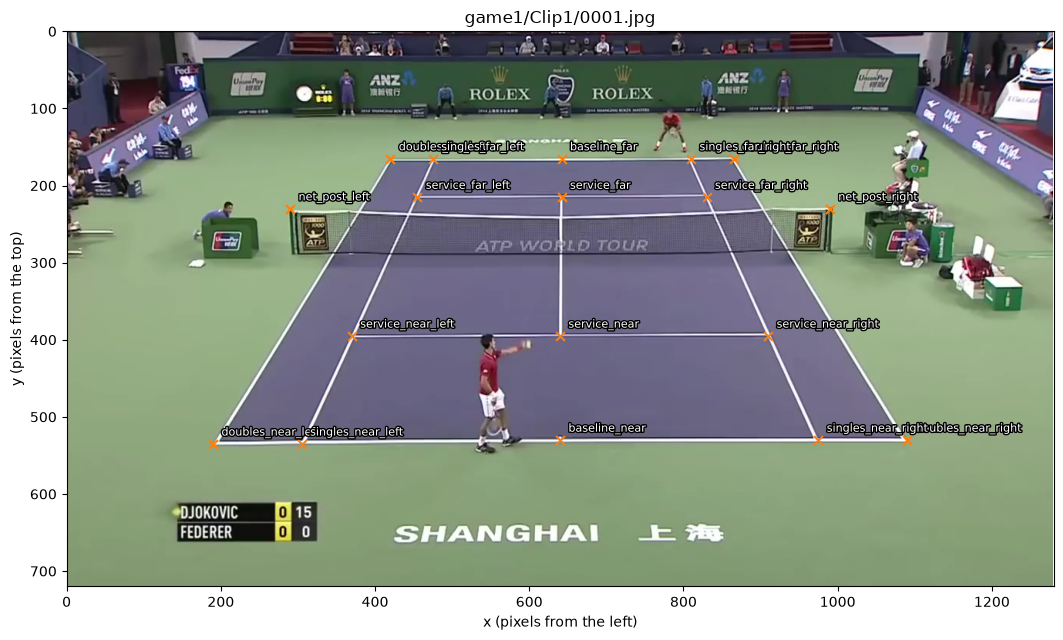

In [63]:
from pathlib import Path
import sys

import cv2
import matplotlib.pyplot as plt
import matplotlib.patheffects as pe
import numpy as np
import yaml

ROOT = Path.cwd().resolve()
if not (ROOT / "configs" / "base_akf.yaml").is_file():
    ROOT = ROOT.parent
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from trajectories.court import catalog

# Path under the dataset. Change the clip and file to the frame you are marking.
FRAME = "game1/Clip1/0001.jpg"

# Pixel of each landmark. x is from the left, y is from the top.
spots = {
    "doubles_near_left": (190, 535),
    "doubles_near_right": (1090, 530),
    "singles_near_left": (305, 535),
    "singles_near_right": (975, 530),
    "doubles_far_left": (420, 165),
    "singles_far_left" : (475, 165),
    "doubles_far_right": (865, 165),
    "singles_far_right": (810, 165),
    "net_post_left": (290, 230),
    "net_post_right": (990, 230),
    "baseline_near" : (640, 530),
    "baseline_far" : (642, 165),
    "service_near_left" : (370,395),
    "service_near_right" : (910, 395),
    "service_far_left" : (455,215),
    "service_far_right" : (830, 215),
    "service_near" : (640, 395),
    "service_far" : (642, 215)
}

with (ROOT / "configs" / "base_akf.yaml").open() as f:
    cfg = yaml.safe_load(f)
dataset = Path(cfg["paths"]["dataset"])
if not dataset.is_absolute():
    dataset = (ROOT / dataset).resolve()

path = dataset / FRAME
bgr = cv2.imread(str(path), cv2.IMREAD_COLOR)
if bgr is None:
    raise FileNotFoundError(path)
image = cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB)
height, width = image.shape[:2]
known = catalog()

fig, ax = plt.subplots(figsize=(12, 6.5))
ax.imshow(image)
print(f"{FRAME}  {width}x{height}")
for name, xy in spots.items():
    x, y = float(xy[0]), float(xy[1])
    if name not in known:
        print(f"{name}: not a landmark name")
    if not (0 <= x < width and 0 <= y < height):
        print(f"{name}: ({x:.0f}, {y:.0f}) is outside the frame")
    ax.scatter(x, y, s=40, c="C1", marker="x", linewidths=1.5)
    ax.annotate(
        name,
        (x, y),
        textcoords="offset points",
        xytext=(6, 6),
        color="white",
        fontsize=8,
        path_effects=[pe.withStroke(linewidth=2, foreground="black")],
    )
    print(f"{name}:")
    print(f"  image: [{x:.1f}, {y:.1f}]")
ax.set_xlim(0, width)
ax.set_ylim(height, 0)
ax.set_xlabel("x (pixels from the left)")
ax.set_ylabel("y (pixels from the top)")
ax.set_title(FRAME)
fig.tight_layout()
plt.show()
